# Fake News Detection Project

## 1. Introduction

This project is all about fighting fake news by building a system that can automatically tell if a news article is real or fake. In today's world of social media and online news, it's becoming harder to know what to believe.

To address this problem, we have built a machine learning model that uses natural language processing techniques to analyse the content of news articles and determine their credibility. The data is the [ISOT Fake News dataset](https://onlineacademiccommunity.uvic.ca/isot/2022/11/27/fake-news-detection-datasets/) from the University of Victoria: real articles collected from Reuters.com and fake articles from websites flagged as unreliable by fact-checkers, mostly from 2016 and 2017.

Our model uses a variety of features, such as the text, title and the length of the article to make its classification decision. We also experimented with different machine learning algorithms and techniques, such as PyTorch, to improve the accuracy and robustness of our system.

## 2. Data Loading and Initial Exploration



### 2.1 Loading the Data



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

In [2]:
fake_df = pd.read_csv('data/Fake.csv')
true_df = pd.read_csv('data/True.csv')

fake_df['label'] = 0  # 0 for fake
true_df['label'] = 1  # 1 for true

df = pd.concat([fake_df, true_df], ignore_index=True)

### 2.2 Initial Data Overview

In [3]:
df.head()
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 44898 entries, 0 to 44897
Data columns (total 5 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   title    44898 non-null  str  
 1   text     44898 non-null  str  
 2   subject  44898 non-null  str  
 3   date     44898 non-null  str  
 4   label    44898 non-null  int64
dtypes: int64(1), str(4)
memory usage: 1.7 MB


title      0
text       0
subject    0
date       0
label      0
dtype: int64

No values are missing, but this does not mean the data is clean: 630 fake articles have an empty text, and several thousand texts are exact duplicates (see 2.3.5).

### 2.3 Exploratory Data Analysis

#### 2.3.1 Class Distribution
Our dataset contains 44,898 articles in total, with:
- 23,481 fake news articles (52.3%)
- 21,417 real news articles (47.7%)

This shows that our dataset is relatively balanced, with a slight skew towards fake news articles. This balance is beneficial for training machine learning models as it reduces the risk of class bias.


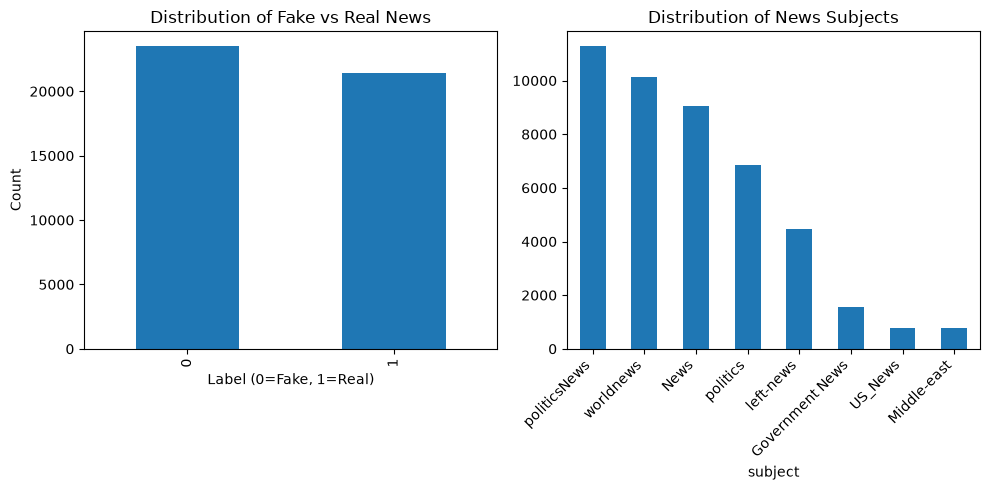

In [4]:
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
df['label'].value_counts().plot(kind='bar')
plt.title('Distribution of Fake vs Real News')
plt.xlabel('Label (0=Fake, 1=Real)')
plt.ylabel('Count')

plt.subplot(1, 2, 2)
df['subject'].value_counts().plot(kind='bar')
plt.title('Distribution of News Subjects')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#### 2.3.2 Subject Analysis
The news articles are distributed across 8 different subjects:
1. Politics News (11,272 articles) - Most common
2. World News (10,145 articles)
3. News (9,050 articles)
4. Politics (6,841 articles)
5. Left News (4,459 articles)
6. Government News (1,570 articles)
7. US News (783 articles)
8. Middle East (778 articles) - Least common

Key observations:
- Political news dominates the dataset, with "politicsNews" being the most frequent category
- There's a clear imbalance in subject distribution
- The subjects do **not overlap at all** between the classes: "politicsNews" and "worldnews" contain only real
  news, and the other six categories contain only fake news
- The subject therefore identifies the label perfectly. It describes how each source organised its articles, not
  whether an article is true, so it cannot be used as a feature

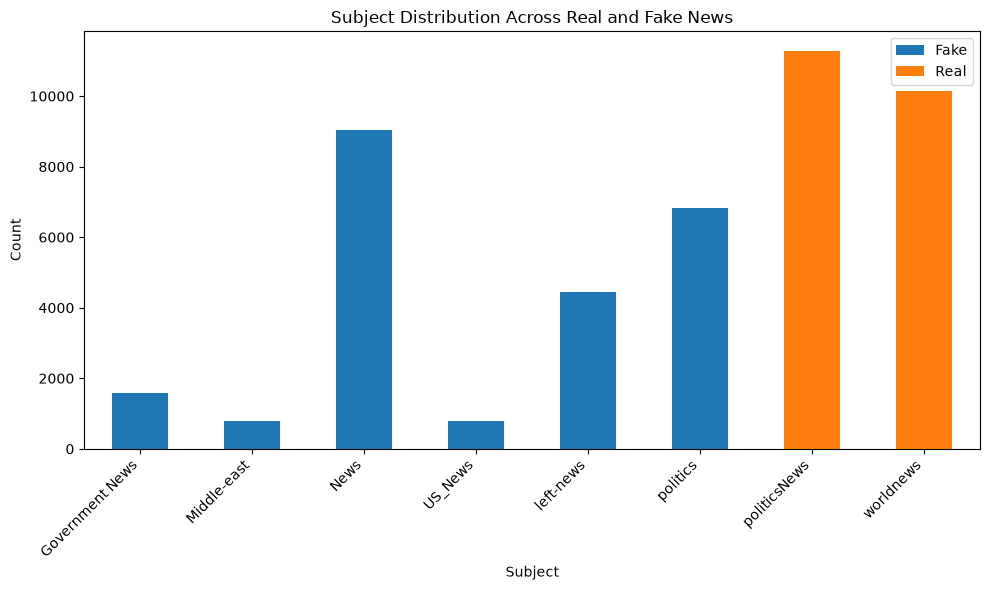

In [5]:
subject_label_dist = pd.crosstab(df['subject'], df['label'])
subject_label_dist.plot(kind='bar', stacked=True, figsize=(10, 6))
plt.title('Subject Distribution Across Real and Fake News')
plt.xlabel('Subject')
plt.ylabel('Count')
plt.legend(['Fake', 'Real'])
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

#### 2.3.3 Text Length Analysis
Analysis of text length distributions reveals:

Title Length:
- Fake news articles tend to have longer titles (median ~85 characters)
- Real news articles have shorter titles (median ~60 characters)
- Both categories show some extreme outliers
- The difference in title length could be a useful feature for classification

Article Text Length:
- Both real and fake news show similar text length distributions
- Most articles fall within a similar length range
- Both categories have significant outliers
- Text length alone might not be a strong discriminator between fake and real news

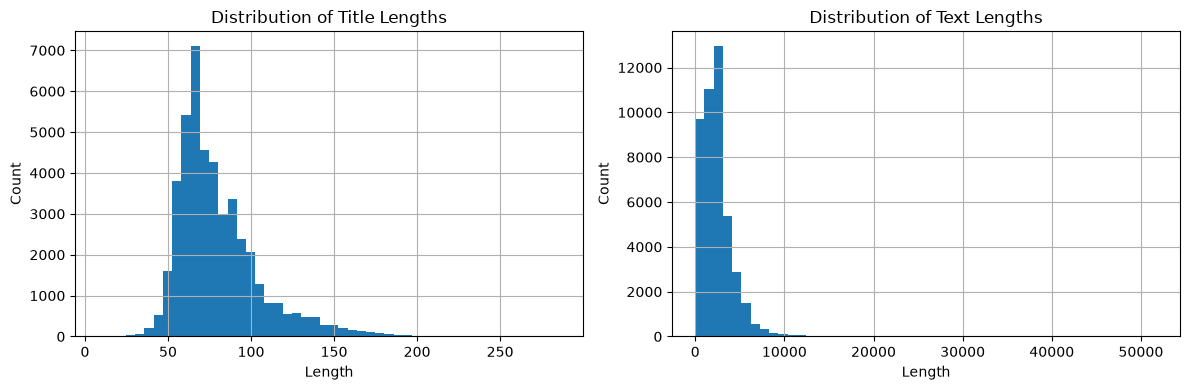

In [6]:
# Visualize text length distributions
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
df['title'].str.len().hist(bins=50)
plt.title('Distribution of Title Lengths')
plt.xlabel('Length')
plt.ylabel('Count')

plt.subplot(1, 2, 2)
df['text'].str.len().hist(bins=50)
plt.title('Distribution of Text Lengths')
plt.xlabel('Length')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

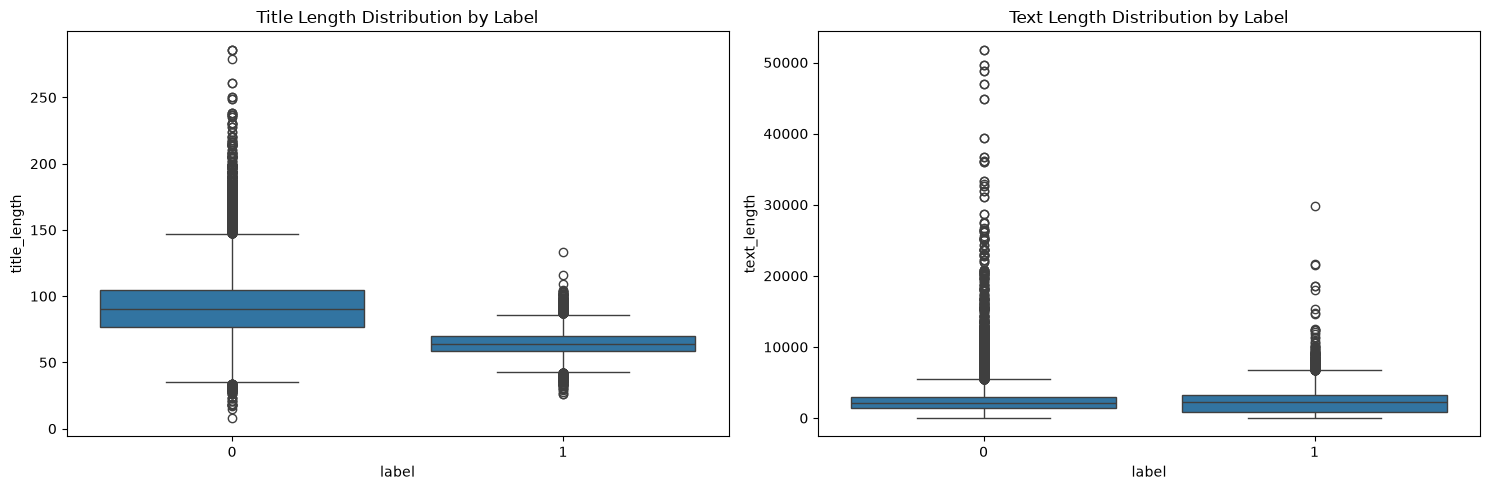

In [7]:
df['title_length'] = df['title'].str.len()
df['text_length'] = df['text'].str.len()

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
sns.boxplot(x='label', y='title_length', data=df)
plt.title('Title Length Distribution by Label')

plt.subplot(1, 2, 2)
sns.boxplot(x='label', y='text_length', data=df)
plt.title('Text Length Distribution by Label')
plt.tight_layout()
plt.show()

#### 2.3.4 Basic Statistics & Example Texts from both Classes

In [8]:
print("\nBasic Statistics:")
print("\nSubject Distribution:")
print(df['subject'].value_counts())
print("\nLabel Distribution:")
print(df['label'].value_counts())


Basic Statistics:

Subject Distribution:
subject
politicsNews       11272
worldnews          10145
News                9050
politics            6841
left-news           4459
Government News     1570
US_News              783
Middle-east          778
Name: count, dtype: int64

Label Distribution:
label
0    23481
1    21417
Name: count, dtype: int64


In [9]:
print("Example of a REAL news article:")
print("Title:", df[df['label']==1]['title'].iloc[0])
print("\nText:", df[df['label']==1]['text'].iloc[0][:500], "...\n")

print("\nExample of a FAKE news article:")
print("Title:", df[df['label']==0]['title'].iloc[0])
print("\nText:", df[df['label']==0]['text'].iloc[0][:500], "...")

Example of a REAL news article:
Title: As U.S. budget fight looms, Republicans flip their fiscal script

Text: WASHINGTON (Reuters) - The head of a conservative Republican faction in the U.S. Congress, who voted this month for a huge expansion of the national debt to pay for tax cuts, called himself a “fiscal conservative” on Sunday and urged budget restraint in 2018. In keeping with a sharp pivot under way among Republicans, U.S. Representative Mark Meadows, speaking on CBS’ “Face the Nation,” drew a hard line on federal spending, which lawmakers are bracing to do battle over in January. When they retur ...


Example of a FAKE news article:
Title:  Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing

Text: Donald Trump just couldn t wish all Americans a Happy New Year and leave it at that. Instead, he had to give a shout out to his enemies, haters and  the very dishonest fake news media.  The former reality show star had just one job to do and he couldn t do

#### 2.3.5 Source Traces and Duplicates

All real articles come from one source (Reuters) and the fake ones from a handful of websites, so the texts carry
traces of their source: the Reuters dateline at the start of real articles, and image credits, links and Twitter
handles in fake ones. The table shows how often each trace appears, and how many texts are empty or duplicated.

In [10]:
traces = {
    '"(Reuters)" in the first 200 characters': df['text'].str[:200].str.contains(r'\(Reuters\)'),
    '"Featured image"': df['text'].str.contains('Featured image'),
    '"Getty Images"': df['text'].str.contains('Getty Images'),
    'pic.twitter.com link': df['text'].str.contains(r'pic\.twitter\.com'),
    'URL': df['text'].str.contains(r'https?://'),
    'empty text': df['text'].str.strip() == '',
    'duplicate text': df.duplicated('text', keep=False),
}
trace_table = pd.DataFrame({name: hit.groupby(df['label']).mean() * 100 for name, hit in traces.items()}).T
trace_table.columns = ['fake (%)', 'real (%)']
print(pd.crosstab(df['subject'], df['label']).rename(columns={0: 'fake', 1: 'real'}))
trace_table.round(1)

label            fake   real
subject                     
Government News  1570      0
Middle-east       778      0
News             9050      0
US_News           783      0
left-news        4459      0
politics         6841      0
politicsNews        0  11272
worldnews           0  10145


,fake (%),real (%)
"""(Reuters)"" in the first 200 characters",0.0,99.1
"""Featured image""",31.0,0.0
"""Getty Images""",16.8,0.0
pic.twitter.com link,14.8,0.0
URL,14.0,0.0
empty text,2.7,0.0
duplicate text,46.7,2.0


#### 2.3.6 Key Findings from EDA
1. **Dataset balance:** 52.3 % fake and 47.7 % real articles, a nearly balanced dataset.

2. **Subject is a shortcut:** the subject categories of real and fake news do not overlap, so the subject alone
   identifies the label. It must not be used as a feature.

3. **Source traces:** 99 % of real texts start with a Reuters dateline, and many fake texts contain image
   credits, links and Twitter handles. A model can learn these instead of anything about truthfulness, so they
   have to be removed before modelling.

4. **Duplicates:** 630 empty fake texts and several thousand duplicated texts. With a random split, copies of
   the same article would end up in both the training and the test set.

5. **Text characteristics:**
   - Fake news tends to have longer, potentially more sensational titles
   - The main text length is not significantly different between classes
   - Example articles show distinct writing styles between fake and real news

6. **Potential features for modelling:** title and text content, title length, stylometric features, sentiment.

#### 2.3.7 Next Steps
Based on the EDA, the modelling notebook:
1. Removes the source traces (Reuters dateline, image credits, links, handles) and the empty and duplicate texts
2. Leaves out the subject and the date
3. Builds features from the text content and writing style
4. Compares the results with and without the shortcuts, to show how much they would inflate the accuracy